> **Working note (not part of the report).** Technical report (deliverable 2, max 8 pages, no cover page). The first
> code cell runs `analysis.py`, the only reference script; every table, the figure and every number quoted come from
> its objects, `output/tables/` and `output/results.txt`. Export: `./export_report.sh` -> `report_technical.pdf`.

In [1]:
%%capture
%run analysis.py

In [2]:
import base64
from IPython.display import HTML, display


def TABLE(title, df, note_text, cls="rtab", index=False):
    """Title, table and note in one block (kept on the same page in the PDF)."""
    html = df.to_html(index=index, border=0, classes=cls, na_rep="")
    display(HTML(f'<div class="tblock"><p class="ttitle">{title}</p>{html}<p class="tnote">{note_text}</p></div>'))


def FIGURE(path, note_text):
    b64 = base64.b64encode(open(path, "rb").read()).decode()
    display(HTML(f'<div class="tblock"><img src="data:image/png;base64,{b64}" alt="Figure D1">'
                 f'<p class="tnote">{note_text}</p></div>'))


REG_NOTE = ("Standard errors clustered by employee in parentheses; * p &lt; 0.10, ** p &lt; 0.05, *** p &lt; 0.01. "
            "log(fee): natural log of the daily fee in CHF (2 or 4). Reference categories: Good transit access, "
            "0 children, FTE 0.6, male. Income = gross income per FTE, centred on the sample mean, in CHF 10'000; age "
            "centred on the mean. Transit classes are terciles within each site, so class effects may differ by site "
            "(class x Lausanne). (a) Lausanne only; (b) to (d) both sites with site and year effects: the fee changed "
            "only in Lausanne in 2025, so log(fee) is the Lausanne x 2025 interaction rescaled by 1 / ln 2.")

# Workplace parking pricing and commuting mode: technical report

This report documents the evidence behind our policy memo on the 2026 parking fee. It answers three questions: how
many employees stopped driving when the Lausanne fee doubled (CHF 2 to 4), what would happen at higher fees, and who
pays. All numbers, tables and the figure are produced by `analysis.py` from `parking_data.csv` and
`transit_access.csv`. Conventions: shares in %, changes in percentage points (pp), elasticities = change in ln(outcome)
/ change in ln(fee), standard errors clustered by employee, 46 working weeks per year.

## 0. Data and cleaning decisions

The data are a balanced panel of 1'000 employees (800 in Lausanne, 200 in Sion) observed in 2024 and 2025 (2'000
rows). We identified five issues and handled them as follows.

1. **Municipality labels.** `home_commune` has 62 spellings (case, hyphens, accents) for 39 municipalities. We
   harmonised them with a normalised key (lower case, no accents or separators). Afterwards no employee changes
   municipality between years, so transit access is fixed per employee.
2. **Missing income.** `gross_income_chf` is missing in 110 rows. Income never differs between years when both are
   observed, so 102 rows were imputed from the same employee's other year. The 8 remaining rows (4 employees, missing
   in both years) get the median income per FTE times their FTE.
3. **Impossible value.** Employee E1001 reports 7.4 car days per week in 2025 (maximum 5). We cap it at 5; dropping
   the observation instead changes the intensive elasticity of Table C2 (c) only from -0.152 to -0.154.
4. **Income and workload.** Income is observed at the contractual FTE (0.6, 0.8 or 1.0). Income terciles therefore use
   income per FTE (cut-offs CHF 80'800 and 105'700, computed over all 1'000 employees), so that a part-time employee
   is not classified as poor; burdens (Part E) use observed income, which is what the employee actually earns.
5. **Age** is identical in both years for every employee; we treat it as measured once (time-invariant control).

## A. Transit accessibility index

**Data collection.** For each of the 39 municipalities we chose the main PT stop and queried the official Swiss
timetable (transport.opendata.ch, which serves SBB / opentransportdata.swiss data) for a regular Tuesday towards
Lausanne or Sion station. Car times come from Google Maps (arrive by 08:00, usual traffic, midpoint of the range
shown). We record (i) the **PT/car time ratio**, using the fastest PT connection arriving between 07:00 and 08:00;
(ii) the **number of departures** between 06:00 and 08:59 with a connection to the site; (iii) the **first possible
arrival** of the day.

**Coding rule.** Each indicator is standardised (z-score over the 39 municipalities) and oriented so that higher means
better access: score = 0.4 z(-ln ratio) + 0.4 z(ln departures) + 0.2 z(-first arrival), rescaled to 0 (worst) to 100
(best). Logs limit the influence of extreme values (e.g. 43 departures in Chavannes). Speed and frequency get the
largest weights because they determine whether PT is a daily alternative; the first arrival only matters for early
shifts. **Classes** are score terciles computed **within each site** (Lausanne cut-offs 50.8 and 74.3; Sion 21.3 and
39.1), because the two sites have very different networks and the policy is decided site by site. Stops, sources,
dates and coding notes for each municipality are in `transit_access.csv`.

In [3]:
TABLE("Table A1. Transit accessibility by site and class (summary of the 39 municipalities)",
      tA1_summary.rename(columns={"Municipalities": "Number of municip."}),
      "Note: medians over the municipalities of each class. PT/car ratio: PT time / car time for an arrival around "
      "08:00 (below 1 = PT faster). Departures: distinct departures 06:00-08:59 with a connection to the site. First "
      "arrival: first possible arrival of the day. Score 0-100 (see text). Employees: employees living in the class "
      "(each observed in both years). Full municipality-level data: transit_access.csv.", cls="rtab a1")

Site,Class,Number of municip.,Employees,PT/car ratio (median),Departures 06:00-09:00 (median),First arrival (median),Score (min-max),Municipalities (by decreasing score)
Lausanne,Good,8,426,0.54,41.0,04:59,74.6-100.0,"Renens, Chavannes-près-Renens, Pully, Lausanne, Crissier, Epalinges, Morges, Ecublens"
Lausanne,Medium,8,240,0.88,15.5,05:30,50.9-74.1,"Lutry, Prilly, Bussigny, Le Mont-sur-Lausanne, Cheseaux-sur-Lausanne, Montpreveyres, Mézières, Romanel-sur-Lausanne"
Lausanne,Poor,8,134,1.10,11.5,06:09,0.0-50.6,"Corcelles-le-Jorat, Cugy, Bottens, Savigny, Froideville, Servion, Ropraz, Vulliens"
Sion,Good,5,122,1.10,12.0,05:19,43.5-87.8,"Conthey, Ardon, Sion, Bramois, Vétroz"
Sion,Medium,5,55,1.13,8.0,06:14,21.5-36.9,"Salins, Savièse, Vex, Grimisuat, Ayent"
Sion,Poor,5,23,1.33,4.0,06:28,9.3-21.0,"Nendaz, Evolène, Arbaz, Hérémence, Saint-Martin"


**Validation.** The ranking is plausible on three counts. (i) The score falls with distance (correlation with mean
reported distance: -0.66); the OSRM road distances we computed match the reported ones (correlation 0.97). (ii) Before
any fee change, the 2024 car share in Lausanne rises from 41.3 % (Good) to 57.5 % (Medium) and 87.3 % (Poor); in Sion
from 47.5 % to 70.9 % and 87.0 %. Across municipalities, the rank correlation between score and 2024 car share is
-0.62. (iii) The classes are robust to the weights: with equal weights, only 4 of 39 municipalities change class (all
at a cut-off). **Limitations.** The timetable is the current one, not that of 2024-2025. Each municipality is
represented by one stop, which ignores the walk between home and stop. Classes are relative within a site, so "Poor"
in Sion is not the same level of access as in Lausanne. Finally, the dimension matters at the margin: with the PT/car
ratio alone, 10 municipalities change class.

## B. Extensive margin: mode choice

**Mode shares and flows (Table B1).** In Lausanne, 80 of the 431 drivers of 2024 left the car (59 for the bus, 21 for
the bike) and nobody started driving: the car share fell from 53.9 % to 43.9 %. In Sion, where the fee stayed at
CHF 2, 6 employees started driving and none stopped (58.5 % to 61.5 %).

In [4]:
TABLE("Table B1. Mode shares by site and year, and gross flows into and out of the car", tB1,
      "Note: N = employees per site and year (balanced panel). Shares in % of employees by main mode. Car -> other: "
      "employees whose main mode was car in 2024 and bus or bike in 2025; other -> car: the reverse. Net change in "
      "number of car users. Change in car share in pp and in % of the 2024 share.")

Site,Year,Fee (CHF/day),N,Car (%),Bus (%),Bike (%),Car -> other,Other -> car,Net change,Change in car share (pp),Change in car share (%)
Lausanne,2024,2,800,53.9,34.0,12.1,,,,,
Lausanne,2025,4,800,43.9,41.4,14.8,80,0,-80,-10.0,-18.6
Sion,2024,2,200,58.5,27.0,14.5,,,,,
Sion,2025,2,200,61.5,24.0,14.5,0,6,6,3.0,5.1


**Percentage points or elasticity?** The two measures answer different questions. The **pp change** (-10.0 pp) says
*how many people* stop driving: 10 pp of 800 employees is 80 drivers, i.e. 80 fewer parking users. This is the
measure we use in the policy memo, because decision makers reason in people and parking spaces. The **elasticity**
(ln(43.9 / 53.9) / ln 2 = -0.30, i.e. -18.6 % of the car share for a doubling of the fee) is a *relative* response per
relative price change. It is comparable across groups with very different baseline shares (a 5 pp drop matters more
where 30 % drive than where 90 % do) and it is the input needed to forecast other fees (Part D).

**Heterogeneity (Table B2).** Groups are fixed in 2024 terms: transit class from Part A, income tercile from income per
FTE, and children under 16 (0, 1, 2 or more). The response is concentrated among employees who have an alternative.
With good access, the car share fell by 12.4 pp (elasticity -0.52); with poor access, by only 1.5 pp (-0.02), although
87 % of them drove. Low income employees responded most (-12.3 pp, -0.42), high income employees least (-8.6 pp,
-0.22). Parents of two or more children barely reduced their car use (-4.5 pp, -0.11), unlike employees with no child
(-0.41) or one child (-0.38).

In [5]:
TABLE("Table B2. Car share by group, Lausanne, 2024 and 2025", tB2,
      "Note: Lausanne employees (N = 800), same employees in both years, group membership fixed. Descriptive "
      "before-after estimates, not model-implied effects. Change in pp. Extensive elasticity = ln(share 2025 / share "
      "2024) / ln(4 / 2). Transit access: terciles of the Part A score within the site. Income tercile: gross income "
      "per FTE, cut-offs CHF 80'800 and 105'700 (computed over all 1'000 employees, hence unequal sizes in Lausanne). "
      "Children: under 16 in the household (2 = 2 or more).", cls="rtab")

Dimension,Group,N employees,Car share 2024 (%),Car share 2025 (%),Change (pp),Extensive elasticity
Overall,All,800,53.9,43.9,-10.0,-0.30
Transit access,Good,426,41.3,28.9,-12.4,-0.52
Transit access,Medium,240,57.5,47.1,-10.4,-0.29
Transit access,Poor,134,87.3,85.8,-1.5,-0.02
Income tercile (FTE),T1 (low),261,48.3,36.0,-12.3,-0.42
Income tercile (FTE),T2 (middle),260,51.2,41.9,-9.2,-0.29
Income tercile (FTE),T3 (high),279,61.6,53.0,-8.6,-0.22
Children < 16,0 children,421,45.1,34.0,-11.2,-0.41
Children < 16,1 child,155,64.5,49.7,-14.8,-0.38
Children < 16,2 or more children,224,62.9,58.5,-4.5,-0.11


**Regression (Table B3).** Equation (1) is a linear probability model of `uses_car` (0/1) on log(fee); coefficients are
in probability units, and the effect of a doubling is the coefficient x ln 2. (a) The Lausanne-only before-after model
reproduces Table B1: a doubling reduces the probability of driving by 10.0 pp (95 % CI 7.9 to 12.1). (b) Adding Sion
with site and year effects nets out the common trend: -13.0 pp (CI 9.8 to 16.2). (c) Controls (transit class, income,
children, distance, age, gender, FTE) are time-invariant in a balanced panel, so they leave the policy coefficient
unchanged (-0.188) but raise the R2 from 0.02 to 0.25: distance (+0.233 per log km), children (+0.17) and income
(+0.026 per CHF 10'000) increase car use. (d) Interactions let the response vary with the three characteristics,
coded as in Table B2 (categories with Good access and 0 children as reference; income per FTE centred, in CHF
10'000). Table B4 turns the column (d) coefficients into group effects. For the reference employee a doubling reduces
car use by 17.2 pp; the response is similar with medium access (16.2 pp) but much weaker with poor access (6.9 pp;
interaction +0.149, p &lt; 0.01) and with two or more children (9.0 pp; +0.118, p &lt; 0.05). Higher income slightly dampens the
response (+0.7 pp per CHF 10'000 per FTE, p &lt; 0.10). This confirms the pattern of Table B2 while holding the other
characteristics constant: access and children are the main sources of heterogeneity, income a secondary one.

**Sion as comparison site.** Sion contributes a counterfactual trend: without any fee change its car share *rose* by
3.0 pp. Netting it out raises the Lausanne effect from 10.0 to 13.0 pp per doubling (column b). Reason for caution:
this assumes that Lausanne would have followed Sion's trend without the fee increase, which two years of data cannot
test, and Sion is small (200 employees) with a different, much less dense PT network (median 12 departures in its
best-served class, against 41 in Lausanne).

In [6]:
TABLE("Table B3. Linear probability model of car use (dependent variable: uses_car, 0/1)", tB3,
      "Note: coefficients in probability units (x 100 = pp). " + REG_NOTE + " Samples: (a) Lausanne employees, 2024 "
      "and 2025 (1'600 observations); (b) to (d) all employees, both years (2'000). Effect of doubling the fee = "
      "coefficient on log(fee) x ln 2 x 100 (reference employee in d).", cls="rtab reg")
TABLE("Table B4. Model-implied effect of doubling the fee by group (column d of Tables B3 and C2)", tB4,
      TABLE_NOTES["table_B4"], cls="rtab b4")

Variable,(a) Lausanne,(b) + Sion,(c) + controls,(d) + interactions
log(fee),-0.144*** (0.015),-0.188*** (0.023),-0.188*** (0.023),-0.248*** (0.034)
log(fee) x Medium access,,,,0.015 (0.037)
log(fee) x Poor access,,,,0.149*** (0.028)
"log(fee) x income (FTE, CHF 10'000)",,,,0.011* (0.006)
log(fee) x 1 child,,,,-0.017 (0.057)
log(fee) x 2 or more children,,,,0.118** (0.046)
Lausanne site,,-0.046 (0.039),-0.141*** (0.049),-0.130*** (0.049)
Year 2025,,0.030** (0.012),0.030** (0.012),0.030** (0.012)
Medium access,,,0.044 (0.076),0.036 (0.080)
Poor access,,,0.080 (0.091),-0.034 (0.093)


Group (other characteristics at reference),Car use: effect of doubling (pp),Car use: 95% CI (pp),Days per driver: elasticity,Days per driver: 95% CI
"Reference (Good access, 0 children, mean income)",-17.2,-21.8 to -12.6,-0.29,-0.36 to -0.23
Medium transit access,-16.2,-21.8 to -10.5,-0.23,-0.30 to -0.17
Poor transit access,-6.9,-11.3 to -2.4,-0.18,-0.23 to -0.12
1 child,-18.4,-25.7 to -11.0,-0.15,-0.21 to -0.08
2 or more children,-9.0,-14.9 to -3.2,-0.15,-0.21 to -0.09
Income + CHF 10'000 per FTE (change vs reference),+0.7,-0.1 to 1.6,+0.003,-0.004 to 0.010


## C. Intensive margin and decomposition

**Descriptive response (Table C1).** Among car users (car_days_per_week &gt; 0), mean days driven per week fell from
3.60 to 3.45 in Lausanne (intensive elasticity -0.06), while they rose from 3.55 to 3.65 in Sion. The reduction is
largest with good access (-0.13) and among employees without children (-0.16); it is close to zero for parents
(-0.03). These are descriptive subgroup estimates comparing all drivers of each year, not model-implied effects.

In [7]:
TABLE("Table C1. Days driven per week among car users, Lausanne, 2024 and 2025", tC1,
      "Note: Lausanne car users (car_days_per_week &gt; 0): 431 in 2024, 351 in 2025. Descriptive before-after "
      "estimates. Intensive elasticity = ln(mean days 2025 / mean days 2024) / ln(4 / 2). Groups as in Table B2. One "
      "2025 value of 7.4 capped at 5.")
TABLE("Table C2. Driving frequency of car users (dependent variable: log(car_days_per_week))", tC2,
      "Note: car users only. Coefficients on log(fee) are elasticities (log-log); other coefficients are approximate "
      "proportional effects. " + REG_NOTE + " Samples: (a) Lausanne car users, 2024 and 2025; (b) to (d) car users of "
      "both sites. Effect of doubling the fee = (2^coefficient - 1) x 100, in % of days (reference employee in d).",
      cls="rtab reg")

Dimension,Group,Days/week 2024,Days/week 2025,Intensive elasticity,N drivers 2024,N drivers 2025
Overall,All,3.60,3.45,-0.06,431,351
Transit access,Good,3.31,3.03,-0.13,176,123
Transit access,Medium,3.66,3.51,-0.06,138,113
Transit access,Poor,3.99,3.85,-0.05,117,115
Income tercile (FTE),T1 (low),3.49,3.36,-0.06,126,94
Income tercile (FTE),T2 (middle),3.60,3.48,-0.05,133,109
Income tercile (FTE),T3 (high),3.68,3.49,-0.08,172,148
Children < 16,0 children,3.26,2.93,-0.16,190,143
Children < 16,1 child,3.54,3.48,-0.03,100,77
Children < 16,2 or more children,4.11,4.01,-0.03,141,131


Variable,(a) Lausanne,(b) + Sion,(c) + controls,(d) + interactions
log(fee),-0.077*** (0.015),-0.114*** (0.022),-0.152*** (0.021),-0.294*** (0.031)
log(fee) x Medium access,,,,0.062** (0.030)
log(fee) x Poor access,,,,0.116*** (0.027)
"log(fee) x income (FTE, CHF 10'000)",,,,0.003 (0.004)
log(fee) x 1 child,,,,0.148*** (0.034)
log(fee) x 2 or more children,,,,0.142*** (0.028)
Lausanne site,,0.010 (0.020),-0.083*** (0.022),-0.065*** (0.021)
Year 2025,,0.026** (0.012),0.022** (0.011),0.023** (0.011)
Medium access,,,0.070*** (0.026),0.029 (0.033)
Poor access,,,0.032 (0.032),-0.051 (0.037)


**Specifications (Table C2).** The coefficient on log(fee) is directly an elasticity. It grows from -0.08 (a) to -0.11
with Sion (b), -0.15 with controls (c) and -0.29 for the reference employee in (d), where poor access (+0.116) and
children (+0.15) strongly dampen the response (Table B4: -0.18 with poor access, -0.15 with children). Unlike in Table
B3, controls change the coefficient, because the composition of the car-user sample changes between years.

**Decomposition (Table C3).** We use the same panel, the same years and log changes throughout. Car days per employee
T are the share of drivers S times days per driver D (non-drivers count 0), so ln T = ln S + ln D and the elasticities
add up exactly: ε_total = ε_extensive + ε_intensive. Before-after in Lausanne: -0.30 + (-0.06) = -0.36. Net of the Sion
trend: -0.37 + (-0.10) = -0.47. **The extensive margin accounts for most of the change (78 % net of Sion, 83 %
before-after)**: the fee works mainly by making people stop driving, not by making drivers come less often.

In [8]:
TABLE("Table C3. Decomposition of the total elasticity of car days per employee", tC3,
      "Note: S = share of car users among all employees of the site; D = mean car days among car users; T = mean car "
      "days per week per employee (0 for non-users) = S x D. Elasticity = change in ln(.) / ln(4 / 2). Net of Sion: "
      "Sion's 2024-2025 change in ln(.) is subtracted (Sion's fee did not change). 95 % CI in brackets: bootstrap by "
      "employee, 999 draws, drawn within each site.")

Margin,Lausanne 2024,Lausanne 2025,Sion 2024,Sion 2025,"Elasticity, Lausanne before-after","Elasticity, net of Sion"
Extensive: share of drivers S,53.9 %,43.9 %,58.5 %,61.5 %,-0.30 [-0.36; -0.24],-0.37 [-0.45; -0.29]
Intensive: days per driver D,3.60,3.45,3.55,3.65,-0.06 [-0.09; -0.04],-0.10 [-0.15; -0.06]
Total: car days per employee T = S x D,1.94,1.51,2.08,2.24,-0.36 [-0.42; -0.30],-0.47 [-0.56; -0.38]


**Selection into the car-user sample (Table C4).** The average driver of 2025 is not the same kind of person as the
average driver of 2024. The 2025 drivers are exactly the 2024 drivers who kept driving, and they differ from the 80
who left: in 2024 they already drove more days (3.73 against 3.07), lived farther away (11.1 against 7.0 km), more
often had poor access (32.8 % against 2.5 %), had higher income per FTE and more children (0.97 against 0.54).
Because the most occasional drivers left, the 2025 mean is pushed up, and the raw change (-0.06) **understates** the
response of those who stay: for the 351 drivers observed in both years, days fell from 3.73 to 3.45 (elasticity -0.11);
with employee and year fixed effects, net of Sion, -0.16 (se 0.028). The controls in (c) and (d) partly correct this
composition effect, which is why the coefficient of Table C2 grows across columns.

In [9]:
TABLE("Table C4. Selection: 2024 characteristics of Lausanne drivers who stay and who leave the car", sel.reset_index(),
      "Note: Lausanne employees who drove in 2024 (N = 431), characteristics measured in 2024 (car days also in 2025 "
      "for stayers). Stayers = drivers in both years, identical to the 2025 drivers since nobody started driving. FTE "
      "income = gross income per FTE. Good / Poor transit access: % of the group.", cls="rtab sel")

"Lausanne, characteristics in 2024",All 2024 drivers,Still drive in 2025 (= 2025 drivers),Leave the car
Employees,431,351,80
Car days/week 2024,3.60,3.73,3.07
Car days/week 2025,,3.45,
Distance (km),10.4,11.1,7.0
Good transit access (%),40.8,35.0,66.2
Poor transit access (%),27.1,32.8,2.5
FTE income (CHF),102'892,104'764,94'676
Children (mean),0.89,0.97,0.54


## D. 2026 tariff scenarios

**Choice of elasticities.** The central forecast uses the net-of-Sion elasticities of Table C3 (extensive -0.37,
intensive -0.10). They remove the common trend, come from one consistent decomposition (so that car share, days and
revenue are mutually coherent), and have a bootstrap interval we can propagate. **Mapping to outcomes.** The
elasticities are applied as constant elasticities to the situation observed in 2025 at CHF 4: S(p) = S(4) (p/4)^-0.37,
D(p) = D(4) (p/4)^-0.10, T = S x D, and revenue = p x T x 46 weeks x 800 employees, which equals the observed 2025
revenue (CHF 223'000) at CHF 4. Since |ε_total| = 0.47 &lt; 1, revenue keeps rising with the fee: each 1 % increase in
the fee raises revenue by about 0.53 %, and there is no revenue-maximising fee in this range.

Fee (CHF/day),Car share (%),"Car share, 95% CI (%)",Days per driver,Car days per employee,Annual revenue (thousand CHF)
4 (2025),43.9,,3.45,1.51,223
5,40.4,39.7 to 41.2,3.37,1.36,251
6,37.8,36.5 to 39.1,3.31,1.25,276
8,34.0,32.1 to 36.0,3.22,1.09,322
10,31.3,29.0 to 33.8,3.14,0.98,362



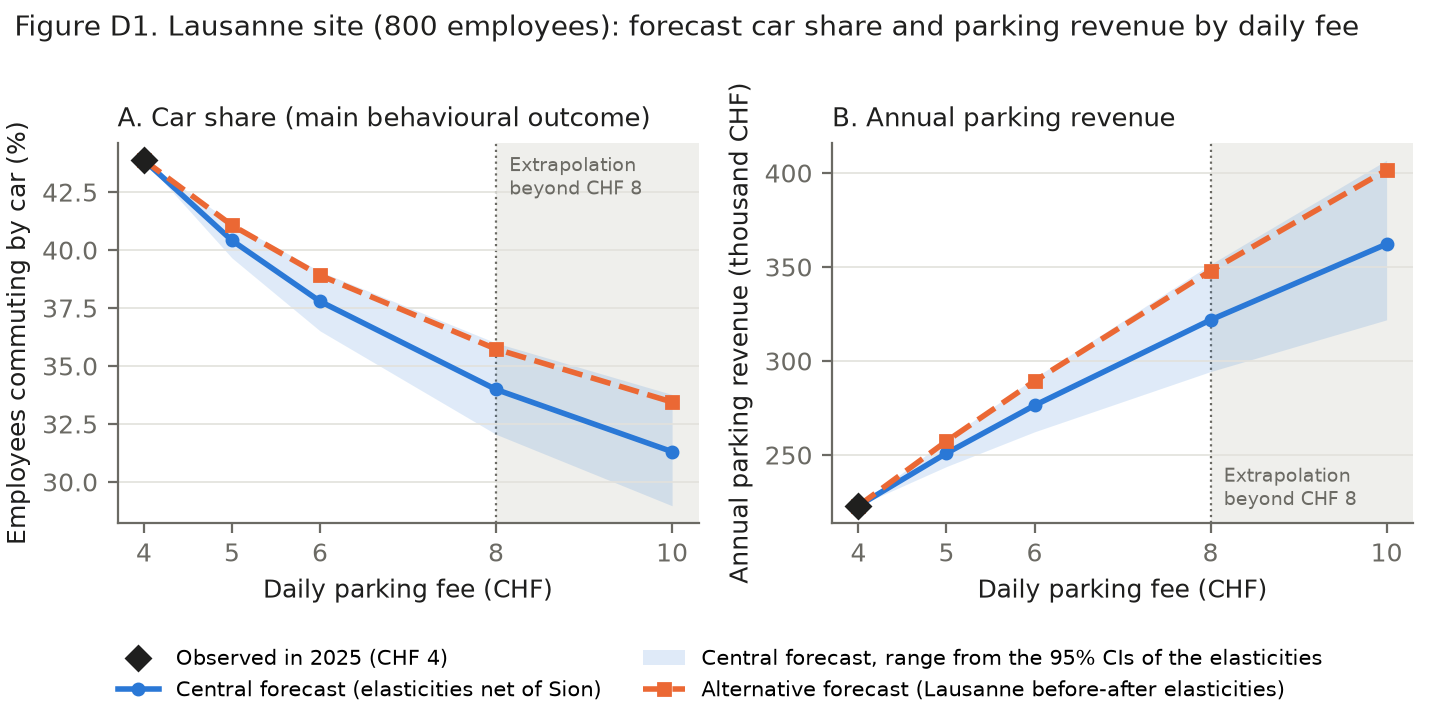

In [10]:
TABLE("Table D1. Forecast outcomes by daily fee, Lausanne site (central scenario)", tD1,
      "Note: Lausanne site (N = 800). Central scenario: constant net-of-Sion elasticities from Table C3 applied to "
      "2025. Car share: % of employees driving. Days per driver: per week. Car days per employee: per week, "
      "non-drivers counted as 0. Annual revenue = fee x car days x 46 weeks, in thousand CHF. 95 % CI: bounds of the "
      "bootstrap intervals of the two elasticities. CHF 10 extrapolates beyond the observed variation.")
FIGURE(FIG / "figure_D1.png",
       "Note: same assumptions as Table D1. Alternative forecast: Lausanne before-after elasticities (Table C3, "
       "-0.30 and -0.06). Shaded band: range from the 95 % CIs of the central elasticities. Grey area beyond CHF 8: "
       "extrapolation.")

**Reading the scenarios.** At CHF 6 the central forecast is 302 drivers (-49 compared with 2025), 200 cars parked on an
average day (242 in 2025) and CHF 276'000 of revenue (+24 %); at CHF 8, 272 drivers, 175 cars and CHF 322'000
(+44 %). The marginal effect declines: 27.7 fewer drivers per extra franc between CHF 4 and 5, 15.2 between 6 and 8,
10.7 between 8 and 10. Sion's revenue (CHF 41'000 at CHF 2) is assumed unchanged.

**Sensitivity (Table D2).** We compare six variants: central, the two CI bounds, the before-after elasticities, class-
specific elasticities (each transit class responds with its own Table B2 / C1 elasticity), and the linear model of
Table B3 (c), which is linear in log fee rather than constant-elasticity. Up to CHF 6 the variants differ by at most
3.0 pp of car share; at CHF 8 by 5.6 pp and at CHF 10 by 7.8 pp. The class-based variant predicts the weakest response,
because as the fee rises the remaining drivers are more and more employees with poor access (32.8 % of drivers at CHF
4, 38.8 % at CHF 8), who barely respond. The linear model predicts the strongest one.

In [11]:
TABLE("Table D2. Sensitivity of the forecast car share (%) to the elasticity used, Lausanne", tD2,
      TABLE_NOTES["table_D2"], cls="rtab small")

Fee (CHF/day),Central,"CI, strong response","CI, weak response",Before-after,By transit class,Linear model B3 (c),Spread (pp),Drivers (central),Cars parked per day (central),"Revenue, central (kCHF)","Revenue, CI (kCHF)"
4 (2025),43.9,43.9,43.9,43.9,43.9,43.9,0.0,351,242,223,223 to 223
5,40.4,39.7,41.2,41.1,41.2,39.7,1.6,323,218,251,244 to 258
6,37.8,36.5,39.1,38.9,39.3,36.3,3.0,302,200,276,262 to 291
8,34.0,32.1,36.0,35.7,36.4,30.9,5.6,272,175,322,294 to 351
10,31.3,29.0,33.8,33.4,34.5,26.7,7.8,250,157,362,322 to 407


**Assumptions and credible range.** The forecasts assume (i) a constant elasticity, (ii) a response completed within
one year, (iii) no other change in mobility policy or PT supply, (iv) no new drivers (none appeared in Lausanne), and
(v) Sion's trend as the counterfactual. We consider **CHF 4 to 8** credible: CHF 8 is one more doubling, the same
proportional change as the one observed (2 to 4). CHF 10 is an extrapolation. The main reason the forecasts may fail
beyond that range is selection: each increase removes the drivers who had an alternative, so the remaining drivers are
increasingly those without one, and the true response should weaken faster than a constant elasticity implies (as
the class-based variant shows). The central forecast is therefore an upper bound on the reduction at high fees.

## E. Distribution and incidence

**Definitions.** Annual parking spending = fee x car days per week x 46 weeks, expressed as % of observed gross income.
(a) averages it over all employees of the group, non-drivers counting 0 (exposure of the group); (b) averages it over
employees who still drive in 2025 (burden of those who pay). (c) projects both under the recommended 2026 policy
(Part F: CHF 4 for poor access, for two or more children outside good access, and for the lowest income tercile; CHF 6
otherwise). Behavioural assumptions for (c): each 2025 driver stays a driver with probability (fee / 4)^ε, with ε the
before-after extensive elasticity of their transit class x children cell (Good / 0-1 children -0.65, Good / 2+ -0.27,
Medium / 0-1 -0.46, Medium / 2+ 0.00, Poor / 0-1 -0.04, Poor / 2+ 0.00), and drives (fee / 4)^ε_int as many days, with
ε_int the class intensive elasticity (Table C1). These group elasticities are used rather than the average one because
the recommended fee varies with the same characteristics. Drivers at CHF 4 are unaffected.

In [12]:
TABLE("Table E1. Annual parking spending as % of gross income, Lausanne, 2025 and recommended 2026 policy", tE1,
      "Note: Lausanne employees (N = 800). Employees, Drivers 2025: group sizes. Reduced rate: % of the group eligible "
      "for CHF 4 under the recommended policy. (a) mean over all employees of the group (0 for non-drivers); (b) mean "
      "over 2025 drivers; (c) projection under CHF 6 / 4 (see text), remaining drivers weighted by their probability of "
      "still driving. Share of 2025 revenue: % of the parking revenue paid by the group. No welfare effect, saving or "
      "unobserved PT cost is inferred.", cls="rtab small")
TABLE("Table E2. Burden of remaining drivers under a uniform fee, Lausanne", tE2, TABLE_NOTES["table_E2"],
      cls="rtab small")

Dimension,Group,Employees,Drivers 2025,Reduced rate (%),"(a) All, 2025 (%)","(b) Drivers, 2025 (%)","(c) All, CHF 6 / 4 (%)","(c) Remaining drivers, CHF 6 / 4 (%)",Share of 2025 revenue (%)
Overall,All,800,351,51.2,0.30,0.69,0.32,0.79,100.0
Transit access,Good,426,123,35.0,0.17,0.57,0.19,0.74,30.8
Transit access,Medium,240,113,52.9,0.33,0.70,0.36,0.82,32.7
Transit access,Poor,134,115,100.0,0.69,0.80,0.69,0.80,36.5
Income tercile (FTE),T1 (low),261,94,100.0,0.35,0.97,0.35,0.97,26.0
Income tercile (FTE),T2 (middle),260,109,27.3,0.30,0.71,0.32,0.85,31.3
Income tercile (FTE),T3 (high),279,148,28.0,0.27,0.50,0.29,0.62,42.6
Children < 16,0 children,421,143,42.5,0.19,0.56,0.20,0.65,34.5
Children < 16,1 child,155,77,42.6,0.35,0.71,0.38,0.85,22.1
Children < 16,2 or more children,224,131,73.7,0.48,0.83,0.51,0.90,43.4


Fee (CHF/day),Expected drivers,Mean spending (CHF/year),Drivers above 1 % of income (%),Drivers above 2 % of income (%),"Burden, poor access (%)","Burden, low income T1 (%)","Burden, 2 or more children (%)",Poor access share of revenue (%)
4 (2025),351,635,12.8,0.0,0.80,0.97,0.83,36.5
5,331,788,27.3,2.1,0.99,1.20,1.02,38.4
6,316,939,45.1,3.4,1.18,1.44,1.21,39.9
8,295,1'239,70.4,11.5,1.55,1.91,1.58,42.2
10,281,1'537,88.1,26.6,1.92,2.37,1.95,44.0


**Does a weak response indicate a low burden?** No. Exposure (a) and burden (b) rank groups differently from the
behavioural response. Employees with poor access barely responded (elasticity -0.02), yet their drivers bear the
highest burden by access group (0.80 % of income, against 0.57 % with good access) and they pay 36.5 % of the revenue
with 16.8 % of the employees. The same holds for parents of two or more children (0.83 %, 43.4 % of revenue). A weak
response here signals a lack of alternatives (they live farther away and have the slowest PT), not indifference to the
price.

**Who benefits and who pays?** The largest behavioural response, and therefore the largest reduction in car use, comes
from employees with good access (-12.4 pp), with one child (-14.8 pp) and with low income (-12.3 pp). The largest
revenue contributions come from parents of two or more children (43.4 %), the high income tercile (42.6 %) and poor
access employees (36.5 %). Low income drivers have the highest burden of all groups (0.97 %), because the fee is a
fixed amount per day.

**Foreseeable problems with a uniform tariff (Table E2).** A uniform increase charges most those who cannot switch. At a
uniform CHF 6, poor access drivers would pay 1.18 % of their income and low income drivers 1.44 %; at CHF 8, 1.55 % and
1.91 %, and 70 % of remaining drivers would spend more than 1 % of their income. Since poor access drivers hardly leave
the car, their share of revenue rises with the fee (36.5 % to 42.2 % at CHF 8): the fee becomes a transfer from those
without an alternative rather than an incentive. Under the recommended policy (Table E1, c), these groups keep their
2025 burden (poor access 0.80 %, low income 0.97 %); the increase falls on middle and high income drivers with an
alternative (good access drivers: 0.57 % to 0.74 %). We do not infer welfare losses, savings or PT costs, which the
data do not contain.

## F. Policy recommendation

**Objective.** We prioritise reducing car days per employee (the demand for parking spaces), under the constraint that
no employee without a realistic alternative and no low income employee pays more than in 2025. Revenue is a means to
fund alternatives, not a goal.

**Recommended package for Lausanne (Sion unchanged at CHF 2, as comparison site).**
(1) A **reduced rate of CHF 4 (unchanged)** for employees living in a Poor access municipality, with two or more
children under 16 outside Good access municipalities, or in the lowest income tercile (income per FTE below CHF
80'800): 410 of 800 employees, 208 of the 351 drivers. (2) A **standard rate of CHF 6 in 2026**, raised to **CHF 8 in
2027 only if** car days per employee are still above 1.33 at the 12-month review. (3) **Revenue recycling**: all
additional revenue funds a CHF 100 contribution per annual PT or bike subscription, first for employees who give up
their parking, then for low income employees; paid by the mobility manager through payroll on proof of subscription,
with rules set jointly with the staff council. (4) **Administration**: eligibility uses data HR already holds
(municipality, children, salary per FTE); only the rate category is sent to the parking system.

**Comparison with alternatives (Table F1).** All options are projected with the same method as Table E1 (c), so they
are directly comparable. Step 1 (F) reduces car days per employee by 7.6 % (1.51 to 1.40; 224 cars parked per day
instead of 242); only 143 drivers pay more, all middle or high income with an alternative (mean income CHF 115'000
against 92'000 at the reduced rate), on average CHF 255 per year, and nobody loses more than CHF 500. Step 2 (G)
reaches -11.9 %, as much as a uniform CHF 6 (C, -11.3 %), with 143 instead of 351 drivers paying more and without
raising the burden of poor access (0.80 % instead of 1.18 %) and low income drivers (0.97 % instead of 1.44 %). We
reject a **uniform CHF 8** (D): it is the most effective option (-18.0 %) but 204 drivers would lose more than CHF 500
per year, including those without an alternative. Protecting **only employees without an alternative** (E) reaches
-15.5 % but raises the burden of low income drivers to 1.29 %. **Trade-off accepted**: low income employees are the
most price-responsive (Table B2), so keeping them at CHF 4 costs some reduction in 2026; we accept it for the guarantee
that no low income employee pays more, and target the subscription contribution at them.

In [13]:
TABLE("Table F1. Projected effects of the policy options, Lausanne site", tF1, TABLE_NOTES["table_F1"],
      cls="rtab small")

Option,Fee (CHF/day),Car days per employee,Change (%),Drivers paying more,Mean increase (CHF/year),"Burden, poor access (%)","Burden, low income (%)",Extra revenue (CHF/year)
A. Status quo,4,1.51,,0,,0.80,0.97,
B. Uniform,5,1.42,-6.5,351,147,0.99,1.20,38'000
C. Uniform,6,1.34,-11.3,351,294,1.18,1.44,74'000
D. Uniform,8,1.24,-18.0,351,587,1.55,1.91,143'000
E. No-alternative only,8 / 4,1.28,-15.5,190,494,0.80,1.29,38'000
F. Recommended 2026,6 / 4,1.40,-7.6,143,255,0.80,0.97,16'000
"G. Step 2, 2027 if needed",8 / 4,1.33,-11.9,143,503,0.80,0.97,29'000


**Uncertainty, unintended effects and limits.** The evidence rests on one fee change over one year, with Sion as
counterfactual, and on small cells (41 employees with poor access and two or more children). The projected reduction
depends on the method: for step 1, -7.4 % (linear model, Table B3 d) to -8.9 % (elasticities net of Sion); for step 2,
-12.3 % to -13.8 %; for a uniform CHF 6, -11.3 % to -16.6 %. Our cell-based method is the most conservative, and Table
D1's central forecast (-17.4 % at a uniform CHF 6) is higher. Possible unintended effects: parking in nearby streets,
drop-offs by family members (car trips not counted in our data), discontinuities at the eligibility thresholds, and
misreporting, which the use of HR records limits. The effect of the subscription contribution is not included in the
projections.

**Implementation and monitoring.** Autumn 2025: publish the rule, the list of municipalities and the subscription
scheme; HR assigns each employee a rate. 1 January 2026: step 1. December 2026: joint review with the staff council.
Indicators: (1) **car days per employee** from parking access records, monthly, formal review at 6 and 12 months;
expected 1.40; trigger: above 1.33 after 12 months, standard rate to CHF 8 in 2027. (2) **Car share of good access
employees** (annual survey, autumn 2026, Sion as comparison); expected about 25 % (28.9 % in 2025); trigger: above 27 %,
strengthen the alternatives before or with step 2. (3) **Parking spending as % of income of poor access and low income
drivers** (payroll and parking records), yearly; trigger: above 0.80 % and 0.97 %, revise the eligibility list or
thresholds. The mobility manager also counts cars parked in nearby streets before and after the change.

**Use of AI.** We used an AI assistant (Claude, Anthropic) to help write and debug `analysis.py`, to format tables and
to draft and edit parts of the text. All results were reproduced by running the script, and the group checked every
number, source and interpretation.

**Sources.** Timetables: transport.opendata.ch API (official SBB / opentransportdata.swiss data). Car times: Google Maps.
Road distances for validation: OSRM (project-osrm.org). Estimation: Python (pandas, statsmodels, matplotlib).